In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

base = "/content/drive/MyDrive/Brock_University/pidgindataset2026October/"

annot_df = pd.read_csv(base+"pidgin_unique_tokens_for_annotated.csv")
df = pd.read_csv(base+"metadata_version2.0.csv")

Mounted at /content/drive


In [2]:
annot_df["language_label"] = annot_df["language_label"].fillna("english")
annot_df["language_label"] = annot_df["language_label"].astype(str).str.lower().str.strip()

# also clean token column
annot_df["token"] = annot_df["token"].astype(str).str.lower().str.strip()

In [4]:
annot_df.drop(columns="frequency", inplace=True)

In [5]:
annot_df.head()

,token,language_label
0,dey,pidgin
1,i,english
2,and,english
3,the,english
4,for,english


In [6]:
cols_to_drop = [
    "pidgin_tokens",
    "code_switch_category",
]

df = df.drop(columns=cols_to_drop, errors="ignore")

In [7]:
df.head()

,speaker_id,audio_path,pidgin_transcription,english_translation,medical_terms_english,medical_terms_pidgen,audio_length,sample_rate,num_channels,speech_rate,signal_to_noise_ratio,silence_ratio,audio,file_exists,text,reference,sample_id,pidgin_word_count,english_word_count,length_ratio
0,Speaker_1,root/audio/Speaker_1/Speaker1-1.wav,e depend on your effort how you take dey do ex...,it all depends on your efforts regarding regul...,"['care', 'knee', 'walk', 'two days', 'one to t...","['exercise', 'everytime', 'after two day', 'no...",19.04,16000.0,1.0,2.678378,54.947548,0.319377,/content/drive/MyDrive/Brock_University/pidgin...,True,e depend on your effort how you take dey do ex...,e depend on your effort how you take dey do ex...,6a840a4ad1fd60283227,51,34,1.500000
1,Speaker_1,root/audio/Speaker_1/Speaker1-2.wav,my daughter make four years two nights ago she...,my daughter is four years old two nights ago s...,"['daughter', 'four years old', 'vomited', 'sor...","['daughter', 'wake up', 'vomited', 'pain', 'ho...",34.48,16000.0,1.0,2.580879,53.953575,0.334655,/content/drive/MyDrive/Brock_University/pidgin...,True,my daughter make four years two nights ago she...,my daughter make four years two nights ago she...,fa777d58c8f323da62e2,89,136,0.654412
2,Speaker_1,root/audio/Speaker_1/Speaker1-3.wav,hi dis na retention cyst e go need excise for ...,hi this is definitely a retention cyst it need...,"['retention cyst', 'mass', 'histopathological ...","['reasons', 'removed', 'important part of the ...",21.97,16000.0,1.0,2.321869,57.647476,0.335672,/content/drive/MyDrive/Brock_University/pidgin...,True,hi dis na retention cyst e go need excise for ...,hi dis na retention cyst e go need excise for ...,01fceaa9e74b77698df4,51,56,0.910714
3,Speaker_1,root/audio/Speaker_1/Speaker1-4.wav,i be thirty one years woman and i get blod clo...,i am a thirty one year old woman with a blood ...,"['thirty one year old woman', 'head injury', '...","['thirty one years woman', 'not', 'head injury...",34.61,16000.0,1.0,2.571562,49.890247,0.308394,/content/drive/MyDrive/Brock_University/pidgin...,True,i be thirty one years woman and i get blod clo...,i be thirty one years woman and i get blod clo...,3d812380dee30f23b366,89,94,0.946809
4,Speaker_1,root/audio/Speaker_1/Speaker1-5.wav,i be forty five years old man my platelet coun...,i am forty five years old male my platelet cou...,"['forty five years old male', 'platelet count'...","['forty five years old man', 'platelet count',...",42.63,16000.0,1.0,2.040783,50.834831,0.307166,/content/drive/MyDrive/Brock_University/pidgin...,True,i be forty five years old man my platelet coun...,i be forty five years old man my platelet coun...,ac3bdc92665cb5600166,87,81,1.074074


In [8]:
token_label_dict = dict(zip(annot_df["token"], annot_df["language_label"]))

print("Total annotated tokens:", len(token_label_dict))
print(annot_df["language_label"].value_counts())

Total annotated tokens: 10145
language_label
english    10018
pidgin       127
127            1
Name: count, dtype: int64


In [9]:
import re
from collections import Counter
import numpy as np

In [10]:
def tokenize(text):
    if pd.isna(text):
        return []

    text = str(text).lower()
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text.split()

df["pidgin_tokens"] = df["pidgin_transcription"].apply(tokenize)

In [11]:
def label_pidgin_tokens(tokens):
    return [token_label_dict.get(token, "unknown") for token in tokens]

df["token_language_labels"] = df["pidgin_tokens"].apply(label_pidgin_tokens)

In [12]:
def code_switch_features(labels):
    valid_labels = [l for l in labels if l not in ["unknown", "other"]]

    total_tokens = len(labels)
    valid_tokens = len(valid_labels)

    english_count = valid_labels.count("english")
    pidgin_count = valid_labels.count("pidgin")

    if valid_tokens == 0:
        english_ratio = np.nan
        pidgin_ratio = np.nan
        ambiguous_ratio = np.nan
        cmi = np.nan
        category = "Unknown"
    else:
        english_ratio = english_count / valid_tokens
        pidgin_ratio = pidgin_count / valid_tokens

        # dominant-language based Code-Mixing Index
        lang_counts = Counter(valid_labels)
        dominant_count = lang_counts.most_common(1)[0][1]
        cmi = (valid_tokens - dominant_count) / valid_tokens

        if cmi == 0:
            category = "No Code-Switch"
        elif cmi < 0.2:
            category = "Low Code-Switch"
        elif cmi < 0.5:
            category = "Moderate Code-Switch"
        else:
            category = "High Code-Switch"

    # switch points: ENGLISH -> PIDGIN or PIDGIN -> ENGLISH
    switch_points = 0
    prev = None

    for label in valid_labels:
        if label == "AMBIGUOUS":
            continue

        if prev is not None and label != prev:
            switch_points += 1

        prev = label

    return pd.Series({
        "total_tokens": total_tokens,
        "valid_labeled_tokens": valid_tokens,
        "english_token_count": english_count,
        "pidgin_token_count": pidgin_count,
        "english_ratio": english_ratio,
        "pidgin_ratio": pidgin_ratio,
        "cmi": cmi,
        "switch_points": switch_points,
        "code_switch_category": category
    })

In [13]:
cols_to_drop = [
    "total_tokens",
    "valid_labeled_tokens",
    "english_token_count",
    "pidgin_token_count",
    "english_ratio",
    "pidgin_ratio",
    "ambiguous_ratio",
    "ambiguous_token_count",
    "unknown_token_count",
]

df = df.drop(columns=cols_to_drop, errors="ignore")

In [14]:
cols_to_drop = [
    "switch_points",
    "code_switch_category",
    "cmi",
]

df = df.drop(columns=cols_to_drop, errors="ignore")

In [21]:
df.head()

,speaker_id,audio_path,pidgin_transcription,english_translation,medical_terms_english,medical_terms_pidgen,audio_length,sample_rate,num_channels,speech_rate,...,token_language_labels,total_tokens,valid_labeled_tokens,english_token_count,pidgin_token_count,english_ratio,pidgin_ratio,cmi,switch_points,code_switch_category
0,Speaker_1,root/audio/Speaker_1/Speaker1-1.wav,e depend on your effort how you take dey do ex...,it all depends on your efforts regarding regul...,"['care', 'knee', 'walk', 'two days', 'one to t...","['exercise', 'everytime', 'after two day', 'no...",19.04,16000.0,1.0,2.678378,...,"[pidgin, english, english, english, english, e...",51,51,39,12,0.764706,0.235294,0.235294,19,Moderate Code-Switch
1,Speaker_1,root/audio/Speaker_1/Speaker1-2.wav,my daughter make four years two nights ago she...,my daughter is four years old two nights ago s...,"['daughter', 'four years old', 'vomited', 'sor...","['daughter', 'wake up', 'vomited', 'pain', 'ho...",34.48,16000.0,1.0,2.580879,...,"[english, english, english, english, english, ...",89,89,69,20,0.775281,0.224719,0.224719,34,Moderate Code-Switch
2,Speaker_1,root/audio/Speaker_1/Speaker1-3.wav,hi dis na retention cyst e go need excise for ...,hi this is definitely a retention cyst it need...,"['retention cyst', 'mass', 'histopathological ...","['reasons', 'removed', 'important part of the ...",21.97,16000.0,1.0,2.321869,...,"[english, pidgin, pidgin, english, english, pi...",51,51,41,10,0.803922,0.196078,0.196078,18,Low Code-Switch
3,Speaker_1,root/audio/Speaker_1/Speaker1-4.wav,i be thirty one years woman and i get blod clo...,i am a thirty one year old woman with a blood ...,"['thirty one year old woman', 'head injury', '...","['thirty one years woman', 'not', 'head injury...",34.61,16000.0,1.0,2.571562,...,"[english, english, english, english, english, ...",89,89,71,18,0.797753,0.202247,0.202247,22,Moderate Code-Switch
4,Speaker_1,root/audio/Speaker_1/Speaker1-5.wav,i be forty five years old man my platelet coun...,i am forty five years old male my platelet cou...,"['forty five years old male', 'platelet count'...","['forty five years old man', 'platelet count',...",42.63,16000.0,1.0,2.040783,...,"[english, english, english, english, english, ...",87,87,79,8,0.908046,0.091954,0.091954,13,Low Code-Switch


In [16]:
cs_df = df["token_language_labels"].apply(code_switch_features)

# Drop old duplicate columns if needed
cols_to_drop = cs_df.columns.intersection(df.columns)
df = df.drop(columns=cols_to_drop, errors="ignore")

df = pd.concat([df, cs_df], axis=1)

In [17]:
code_switch_dist = (
    df["code_switch_category"]
    .value_counts()
    .reset_index()
)

code_switch_dist.columns = ["category", "count"]

code_switch_dist["percentage"] = (
    code_switch_dist["count"] / len(df) * 100
).round(2)

code_switch_dist

,category,count,percentage
0,Low Code-Switch,7842,76.75
1,Moderate Code-Switch,2306,22.57
2,No Code-Switch,69,0.68
3,High Code-Switch,1,0.01


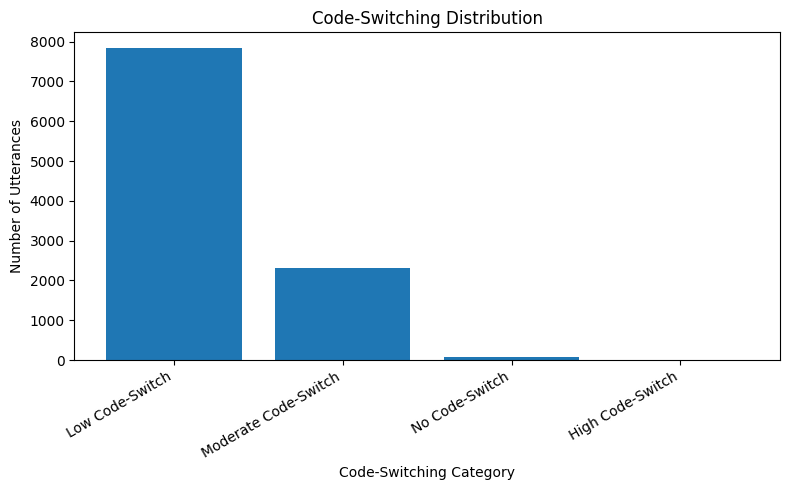

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.bar(
    code_switch_dist["category"],
    code_switch_dist["count"]
)

plt.title("Code-Switching Distribution")
plt.xlabel("Code-Switching Category")
plt.ylabel("Number of Utterances")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [19]:
df.head()

,speaker_id,audio_path,pidgin_transcription,english_translation,medical_terms_english,medical_terms_pidgen,audio_length,sample_rate,num_channels,speech_rate,...,token_language_labels,total_tokens,valid_labeled_tokens,english_token_count,pidgin_token_count,english_ratio,pidgin_ratio,cmi,switch_points,code_switch_category
0,Speaker_1,root/audio/Speaker_1/Speaker1-1.wav,e depend on your effort how you take dey do ex...,it all depends on your efforts regarding regul...,"['care', 'knee', 'walk', 'two days', 'one to t...","['exercise', 'everytime', 'after two day', 'no...",19.04,16000.0,1.0,2.678378,...,"[pidgin, english, english, english, english, e...",51,51,39,12,0.764706,0.235294,0.235294,19,Moderate Code-Switch
1,Speaker_1,root/audio/Speaker_1/Speaker1-2.wav,my daughter make four years two nights ago she...,my daughter is four years old two nights ago s...,"['daughter', 'four years old', 'vomited', 'sor...","['daughter', 'wake up', 'vomited', 'pain', 'ho...",34.48,16000.0,1.0,2.580879,...,"[english, english, english, english, english, ...",89,89,69,20,0.775281,0.224719,0.224719,34,Moderate Code-Switch
2,Speaker_1,root/audio/Speaker_1/Speaker1-3.wav,hi dis na retention cyst e go need excise for ...,hi this is definitely a retention cyst it need...,"['retention cyst', 'mass', 'histopathological ...","['reasons', 'removed', 'important part of the ...",21.97,16000.0,1.0,2.321869,...,"[english, pidgin, pidgin, english, english, pi...",51,51,41,10,0.803922,0.196078,0.196078,18,Low Code-Switch
3,Speaker_1,root/audio/Speaker_1/Speaker1-4.wav,i be thirty one years woman and i get blod clo...,i am a thirty one year old woman with a blood ...,"['thirty one year old woman', 'head injury', '...","['thirty one years woman', 'not', 'head injury...",34.61,16000.0,1.0,2.571562,...,"[english, english, english, english, english, ...",89,89,71,18,0.797753,0.202247,0.202247,22,Moderate Code-Switch
4,Speaker_1,root/audio/Speaker_1/Speaker1-5.wav,i be forty five years old man my platelet coun...,i am forty five years old male my platelet cou...,"['forty five years old male', 'platelet count'...","['forty five years old man', 'platelet count',...",42.63,16000.0,1.0,2.040783,...,"[english, english, english, english, english, ...",87,87,79,8,0.908046,0.091954,0.091954,13,Low Code-Switch


In [20]:
df.to_csv(base+"metadata_versionCodeSwitching.0.csv", index=False)